## Explore the effects that manditory military service may have on lifetime earnings and overall economic effects in a country

## Countries with Manditory Military Service:
* Singapore: 22-24 Months
* Finland: 6-12 Months
* Sweeden: 9-11 Months, Gender Neutral
* Israel: 32 Months for Men, 24 Months for Women
* Taiwan: 1 Year
* South Korea: 18 Months

## Data Sources:
* OECD: https://www.oecd.org/en.html
* KOSIS: https://kosis.kr/eng/
* KEIS: https://www.keis.or.kr/keis/en/index.do

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
import requests 
from io import StringIO
import numpy as np
from scipy import stats, optimize

In [15]:
COUNTRIES = pd.DataFrame([
    # code, name, group, service months (men), women serve?, how many serve, year abolished, note
    ("KOR", "Korea", "Conscription", 18, False, "Universal", None, "20 navy, 21 air force"),
    ("ISR", "Israel", "Conscription", 32, True, "Universal", None, "~24 months for women"),
    ("GRC", "Greece", "Conscription", 12, False, "Universal", None, ""),
    ("TUR", "Türkiye", "Conscription", 6, False, "Universal", None, "paid exemption available"),
    ("FIN", "Finland", "Conscription", 8, False, "Universal", None, "5.5, 8.5 or 11.5 months"),
    ("EST", "Estonia", "Conscription", 10, False, "Universal", None, "8 or 11 months"),
    ("CHE", "Switzerland", "Conscription", 8, False, "Universal", None, "~245 days in blocks over years"),
    ("AUT", "Austria", "Conscription", 6, False, "Universal", None, "or 9 months civilian service"),
    ("LTU", "Lithuania", "Conscription", 9, False, "Selective", 2008, "reinstated 2015"),
    ("LVA", "Latvia", "Conscription", 11, False, "Selective", 2007, "reinstated 2023"),
    ("NOR", "Norway", "Conscription", 12, True, "Selective", None, "women since 2015"),
    ("SWE", "Sweden", "Conscription", 11, True, "Selective", 2010, "reinstated 2017; 9-15 months"),
    ("DNK", "Denmark", "Conscription", 4, False, "Selective", None, "rising to 11 months and women from 2026"),
    ("COL", "Colombia", "Conscription", 18, False, "Selective", None, "12 months for high-school graduates"),
    ("MEX", "Mexico", "Conscription", 12, False, "Nominal", None, "mostly weekend sessions"),
    ("SGP", "Singapore", "Conscription", 24, False, "Universal", None, "not in OECD data"),
    ("TWN", "Taiwan", "Conscription", 12, False, "Universal", None, "4 months 2018-2023; not in OECD data"),
    ("CYP", "Cyprus", "Conscription", 14, False, "Universal", None, "not in OECD data"),
    ("FRA", "France", "Abolished", 0, False, "", 2001, ""),
    ("ESP", "Spain", "Abolished", 0, False, "", 2001, ""),
    ("ITA", "Italy", "Abolished", 0, False, "", 2005, ""),
    ("DEU", "Germany", "Abolished", 0, False, "", 2011, "suspended"),
    ("NLD", "Netherlands", "Abolished", 0, False, "", 1996, "suspended"),
    ("BEL", "Belgium", "Abolished", 0, False, "", 1994, "suspended"),
    ("PRT", "Portugal", "Abolished", 0, False, "", 2004, ""),
    ("POL", "Poland", "Abolished", 0, False, "", 2009, "suspended"),
    ("CZE", "Czechia", "Abolished", 0, False, "", 2005, ""),
    ("HUN", "Hungary", "Abolished", 0, False, "", 2004, "suspended"),
    ("SVK", "Slovak Republic", "Abolished", 0, False, "", 2006, ""),
    ("SVN", "Slovenia", "Abolished", 0, False, "", 2003, ""),
    ("USA", "United States", "All-volunteer", 0, False, "", 1973, "draft ended 1973"),
    ("GBR", "United Kingdom", "All-volunteer", 0, False, "", 1960, "National Service ended 1960"),
    ("CAN", "Canada", "All-volunteer", 0, False, "", None, ""),
    ("AUS", "Australia", "All-volunteer", 0, False, "", 1972, ""),
    ("JPN", "Japan", "All-volunteer", 0, False, "", None, ""),
    ("NZL", "New Zealand", "All-volunteer", 0, False, "", 1972, ""),
    ("IRL", "Ireland", "All-volunteer", 0, False, "", None, ""),
], columns=["code", "name", "group", "service_months", "women_serve", "coverage", "ended", "note"]).set_index("code")
COUNTRIES["ended"] = COUNTRIES["ended"].astype("Int64")

OECD_CODES = []
for c in COUNTRIES.index:
    if c not in ["SGP", "TWN", "CYP"]:
        OECD_CODES.append(c)
OECD_KEY_COUNTRIES = "+".join(OECD_CODES)

AGE_BANDS = ["Y15T19", "Y20T24", "Y25T29", "Y30T34", "Y35T39", "Y40T44", "Y45T49", "Y50T54", "Y55T59", "Y60T64"]
employment =  {
        "agency": "OECD.ELS.SAE", 
        "dataset": "DSD_LFS@DF_LFS_INDIC", 
        "version": "1.1",
        "settings": f"{OECD_KEY_COUNTRIES}.EMP_RATIO..M+F.{'+'.join(AGE_BANDS)}.", 
        "date": "startPeriod=1985",
        "format": "format=csvfilewithlabels",
    }
age_wage_gap = {
        "agency": "OECD.ELS.SAE",
        "dataset": "DSD_EARNINGS@AGE_WAGE_GAP",
        "version": "1.0",
        "settings": f"{OECD_KEY_COUNTRIES}......",
        "date": "startPeriod=2010",
        "format": "format=csvfilewithlabels",
    }
avg_wage = {
        "agency": "OECD.ELS.SAE",
        "dataset": "DSD_EARNINGS@AV_AN_WAGE",
        "version": "1.0",
        "settings": f"{OECD_KEY_COUNTRIES}......",
        "date": "startPeriod=2015",
        "format": "format=csvfilewithlabels",
    }

server = "https://sdmx.oecd.org/public/rest/data"
def createurl(parts):
    return f"{server}/{parts["agency"]},{parts["dataset"]},{parts["version"]}/{parts["settings"]}?{parts["date"]}&{parts["format"]}"

In [16]:
print(createurl(avg_wage))

https://sdmx.oecd.org/public/rest/data/OECD.ELS.SAE,DSD_EARNINGS@AV_AN_WAGE,1.0/KOR+ISR+GRC+TUR+FIN+EST+CHE+AUT+LTU+LVA+NOR+SWE+DNK+COL+MEX+FRA+ESP+ITA+DEU+NLD+BEL+PRT+POL+CZE+HUN+SVK+SVN+USA+GBR+CAN+AUS+JPN+NZL+IRL......?startPeriod=2015&format=csvfilewithlabels


In [17]:
def load_OECD_dataset(settings):
    url = createurl(settings)
    response = requests.get(url)
    df = pd.read_csv(StringIO(response.text))
    return df



employment_df = load_OECD_dataset(employment)
employmentPivot = (
    employment_df.pivot_table(index=["REF_AREA", "TIME_PERIOD", "AGE"], columns="SEX", values="OBS_VALUE").rename(columns={"M": "male", "F": "female"}).reset_index().rename(columns={"REF_AREA": "code", "TIME_PERIOD": "year", "AGE": "age"}).dropna(subset=["male", "female"])
)
employmentPivot.head(10)

SEX,code,year,age,female,male
0,AUS,1985,Y15T19,47.171112,48.381738
1,AUS,1985,Y20T24,66.432219,79.153976
2,AUS,1985,Y25T29,54.490797,86.857471
3,AUS,1985,Y30T34,51.692164,88.941216
4,AUS,1985,Y35T39,56.345773,90.732239
5,AUS,1985,Y40T44,59.428521,89.983610
6,AUS,1985,Y45T49,54.520375,88.228841
7,AUS,1985,Y50T54,41.932693,82.645444
8,AUS,1985,Y55T59,27.063704,71.873862
9,AUS,1985,Y60T64,11.663596,40.514041


In [18]:
focuscolor = "#eb6834"

Comparing Korea to another country with conscription and the USA to see if workforce participation by gender and age was effected by it.
Observations: It seems like the female workforce participation is higher than the male participation during the earlier years when males may be forced to serve and overall the peak of male employment in manditory service countries is lower than in those without it.

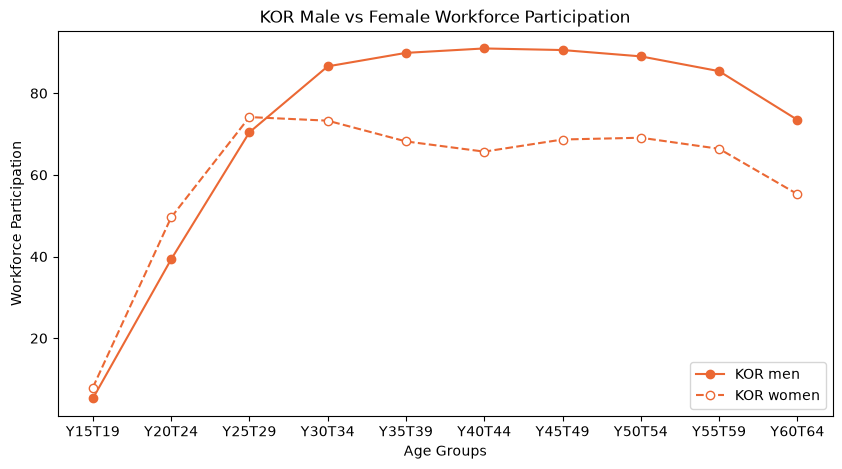

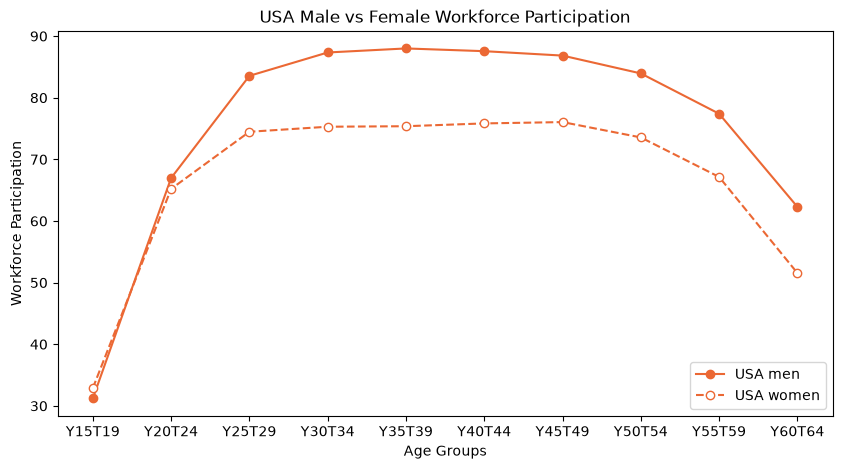

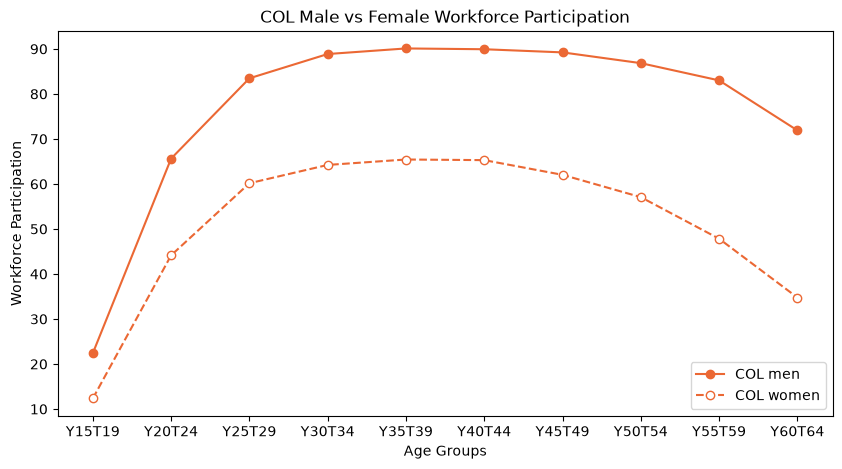

In [19]:
def plotwfparticipation(country, startyear, endyear):
    data = employmentPivot[employmentPivot["year"].between(startyear, endyear)]
    data = data[data["code"] == country]
    data = data.groupby(["code", "age"])[["male", "female"]].mean().reset_index()
    x = []
    for age in AGE_BANDS:
        x.append(age)
    fig, ax = plt.subplots(figsize = (10, 5))
    ax.plot(x, data["male"], marker = "o", color = focuscolor, label = f"{country} men")
    ax.plot(x, data["female"], marker = "o", ls = "--", color = focuscolor, label = f"{country} women", mfc = "white")
    ax.set_title(f"{country} Male vs Female Workforce Participation")
    ax.set_xlabel("Age Groups")
    ax.set_ylabel("Workforce Participation")
    ax.legend(loc = "lower right")
    plt.show()
plotwfparticipation("KOR", 2023, 2025)
plotwfparticipation("USA", 2023, 2025)
plotwfparticipation("COL", 2023, 2025)



Visualize actual wages lost by people in countries with conscription

In [20]:
startage = 20
endage = 65
discrate = .03
conscripts = COUNTRIES[COUNTRIES["group"] == "Conscription"]
wage_gap_df = load_OECD_dataset(age_wage_gap)
wage_df = load_OECD_dataset(avg_wage)
men = wage_gap_df[wage_gap_df["SEX"] == "M"].sort_values("TIME_PERIOD")
men = men[["MEASURE", "REF_AREA", "OBS_VALUE", "Reference area", "Measure"]]
men_gaps = men.groupby(["REF_AREA", "MEASURE"])["OBS_VALUE"].last().unstack()
men_gaps = men_gaps.fillna(men_gaps.median())
men_gaps.head(10)

MEASURE,S_PA_WP,Y_PA_WP
REF_AREA,,
AUS,-8.134826,41.995580
AUT,-11.997406,31.139210
BEL,-25.217772,33.548875
CAN,1.824667,41.431158
CHE,-15.065113,39.141896
COL,0.535613,42.786846
CZE,8.108131,33.981416
DEU,-4.605052,36.466165
DNK,-6.160936,37.166579


In [21]:
columnstokeep = ["OBS_VALUE", "REF_AREA", "TIME_PERIOD", "PRICE_BASE", "UNIT_MEASURE"]
wage_df = wage_df[columnstokeep]
wage_df = wage_df[(wage_df["PRICE_BASE"] == "Q") & (wage_df["UNIT_MEASURE"] == "USD_PPP")]
wages_ave = wage_df.sort_values("TIME_PERIOD").groupby("REF_AREA")["OBS_VALUE"].last()
wages_ave.head(5)

REF_AREA
AUS    72018.439
AUT    78301.337
BEL    80008.652
CAN    67900.601
CHE    92285.059
Name: OBS_VALUE, dtype: float64

Find lifetime earnings of each country using the earnings that they get and trying to best estimate how much they would make each year based on the wagegaps from our wagegap data.

In [22]:
def fit_profile(youth_gap, senior_gap):
    youth, prime, senior = np.arange(20, 25), np.arange(25, 55), np.arange(55, 65)
    targets = np.log([1.0, 1 - youth_gap / 100, 1 - senior_gap / 100])
    def curve(p, ages):
        t = (np.asarray(ages, dtype=float) - 40) / 10  
        return np.exp(p[0] + p[1] * t + p[2] * t ** 2)
    def equations(p):
        prime_avg = curve(p, prime).mean()
        return [np.log(prime_avg) - targets[0],
                np.log(curve(p, youth).mean() / prime_avg) - targets[1],
                np.log(curve(p, senior).mean() / prime_avg) - targets[2]]
    params = optimize.fsolve(equations, [0.0, 0.1, -0.05])  # rising then flattening is best guess
    return lambda ages: curve(params, ages)

def getlifetimeearnings(wages, profile, yearsdelayed):
    ages = np.arange(startage, endage, 1/12)
    workingyears = ages >= startage + yearsdelayed
    payshare = np.where(workingyears, wages/12 * profile(ages - yearsdelayed), 0)
    return (payshare * (1 + discrate)**-(ages - 20)).sum()

This table outlines the monthly remuneration for South Korean military conscripts by rank.

| Rank | Monthly Remuneration (KRW) | Monthly Remuneration (USD) |
| :--- | :--- | :--- |
| Sergeant | 1,500,000 won | ~$1,125 USD |
| Corporal | 1,200,000 won | ~$900 USD |
| Private First Class | 900,000 won | ~$675 USD |
| Private | 750,000 won | ~$562.50 USD |

Source: https://www.easylaw.go.kr/CSP/CnpClsMain.laf?ccfNo=2&cciNo=2&cnpClsNo=1&csmSeq=1461&popMenu=ov&

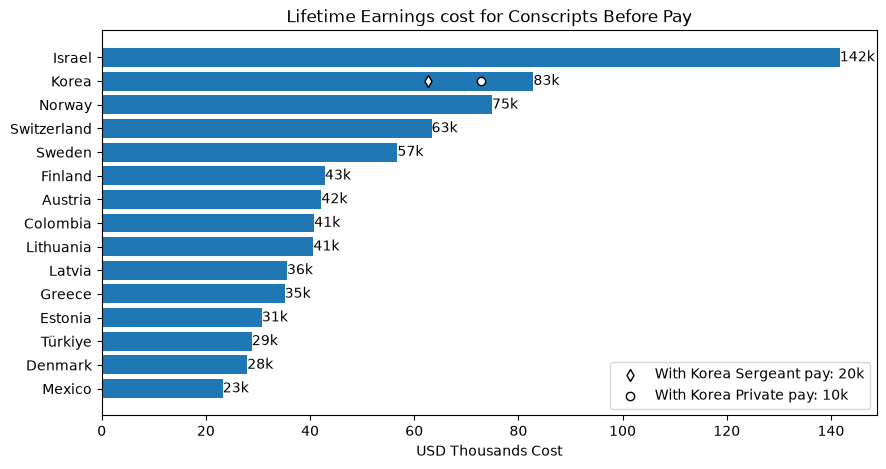

In [37]:
sergeantpayment = 1125 * 18
privatepayment = 562.5 * 18

lifetimecosts = {}
for code, row in conscripts.iterrows():
    if code not in men_gaps.index:
        continue
    youthgap = men_gaps.loc[code, "Y_PA_WP"]
    seniorgap = men_gaps.loc[code, "S_PA_WP"]
    profile = fit_profile(youthgap, seniorgap)
    earningsnoservice = getlifetimeearnings(wages_ave[code], profile, 0)
    earningsservice = getlifetimeearnings(wages_ave[code], profile, row["service_months"] / 12)
    lifetimecosts[row["name"]] = earningsnoservice - earningsservice
lifetimecosts = pd.Series(lifetimecosts).sort_values()
fig, ax = plt.subplots(figsize = (10, 5))
ax.barh(lifetimecosts.index, lifetimecosts.values / 1000)
koreaindex = list(lifetimecosts.index).index("Korea")
ax.scatter(list(lifetimecosts.values)[koreaindex] / 1000 - sergeantpayment / 1000, koreaindex, marker = "d", label = f"With Korea Sergeant pay: {sergeantpayment / 1000:.0f}k", color = "white", edgecolors="black")
ax.scatter(list(lifetimecosts.values)[koreaindex] / 1000 - privatepayment / 1000, koreaindex, marker = "o", label = f"With Korea Private pay: {privatepayment / 1000:.0f}k", color = "white", edgecolors="black")
for index, value in enumerate(lifetimecosts.values):
    ax.text(value/1000, index, f"{value/1000:.0f}k", va = "center")
ax.set_xlabel("USD Thousands Cost")
ax.set_title("Lifetime Earnings cost for Conscripts Before Pay")
ax.legend(loc = "lower right")
plt.show()

It seems like countries with conscription cause a higher percentage of females in the workforce in the earlier years when some men may be forced to serve and this is also shown to effect the overall peaks of male employments in which countries with manditory conscription have lower peaks of males in the workforce. In Korea, the average male that is forced to serve seems to lose about $83,000 USD which is second highest only behind Israel. Additionally the pay that a conscript may receive from serving is very small comapred to their total earnings lost, not really compensating for their overall service time. South Korea has about 300,000 people in their standing military at a time, which means that they must conscript about 200,000 people a year. Due to South Korea's declining birthrates, there were only about 254,500 births, if roughly half of those are male, that means that there would only be about 125,000 males able to be conscripted in 18 years which is well below the required amount that Korean needs to sustain the size of their military. This is also assuming 100% male survival rate to the age of 18.

Source: https://www.theguardian.com/world/2026/feb/25/south-korea-birth-rate-increase-rise-echo-boomers 